# DATA 245 | Person 3: Retraining strategies and the full experiment

Runs the three retraining strategies (static, periodic, drift-triggered) on all four scenarios, with Person 2's two shortlisted models and the three predeclared seeds, and saves one row per window to `results/results.csv`.

**Fair comparison (TA feedback #3).** Every run goes through one function, `src.strategies.run_strategy`. All three strategies get the same scenario object (same rows), the same model configuration and features, the same seed, the same label-delay rule, the same retraining data rule and the same threshold rule, and they start from one shared initial model. The only difference is `should_retrain()`.

**Settings.** Every setting comes from `src/settings.py`. Window size, label delay, periodic interval, drift rule, seeds, retraining data and the threshold rule are **PROPOSED defaults, not confirmed decisions** (see `DECISIONS.md`).

This notebook only *produces* the results and runs sanity checks. The analysis (charts per scenario, comparison tables, statistical tests, alerts vs. performance drops) is Person 4's `07_results.ipynb`.

In [1]:
import sys
from pathlib import Path
p = Path.cwd().resolve()
root = p if (p / 'src').exists() else p.parent
sys.path.insert(0, str(root))

import time
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load_dataset
from src.scenarios import all_scenarios
from src.settings import (EXPERIMENT_FEATURE_SET, EXPERIMENT_MODELS, LABEL_DELAY_WINDOWS, N_STREAM_WINDOWS,
                          PERIODIC_EVERY_WINDOWS, PSI_ALERT, RETRAIN_DATA, SEEDS, STRATEGIES,
                          THRESHOLD_TUNE_ROWS, TRIGGER_GROUPS)
from src.strategies import run_experiment, summarise

warnings.filterwarnings('ignore', category=UserWarning)   # sklearn feature-name notices
pd.set_option('display.width', 200)
print('Project root:', root)

Project root: /home/claude/work


## 1. Settings used in this run

In [2]:
settings = pd.Series({
    'models (Person 2 shortlist)': ', '.join(EXPERIMENT_MODELS),
    'feature set': EXPERIMENT_FEATURE_SET,
    'strategies': ', '.join(STRATEGIES),
    'seeds': SEEDS,
    'windows per stream': N_STREAM_WINDOWS,
    'label delay (windows)': LABEL_DELAY_WINDOWS,
    'periodic: retrain every (windows)': PERIODIC_EVERY_WINDOWS,
    'drift rule': f'retrain when any feature in {TRIGGER_GROUPS} has PSI > {PSI_ALERT}',
    'retraining data': RETRAIN_DATA,
    'threshold rule': f'best F1 on the most recent {THRESHOLD_TUNE_ROWS} labelled rows, re-tuned at every fit',
})
settings.to_frame('value')

,value
models (Person 2 shortlist),"Logistic Regression, Linear SVM"
feature set,baseline_10
strategies,"static, periodic, drift_triggered"
seeds,"[42, 43, 44]"
windows per stream,8
label delay (windows),1
periodic: retrain every (windows),2
drift rule,retrain when any feature in ['customer_history...
retraining data,expanding
threshold rule,"best F1 on the most recent 1030 labelled rows,..."


## 2. Run the full grid

4 scenarios × 3 strategies × 2 models × 3 seeds, 8 windows each. The real replay does not depend on the seed and both models are deterministic, so its three seeds give identical rows; they are kept so that every scenario has the same number of runs.

In [3]:
df = load_dataset()
start = time.perf_counter()
results = run_experiment(df, seeds=SEEDS)
print(f'Total run time: {time.perf_counter() - start:.0f} s')
results.shape

seed 42  real_replay  Logistic Regression  done in  11.0 s


seed 42  real_replay  Linear SVM           done in   9.3 s


seed 42  stationary   Logistic Regression  done in   6.3 s


seed 42  stationary   Linear SVM           done in   6.1 s


seed 42  sudden       Logistic Regression  done in   6.9 s


seed 42  sudden       Linear SVM           done in   7.3 s


... (15 outputs left out)

seed 44  sudden       Linear SVM           done in   8.1 s


seed 44  gradual      Logistic Regression  done in   8.1 s


seed 44  gradual      Linear SVM           done in   8.3 s
Total run time: 191 s


(576, 39)

## 3. Sanity checks before saving

In [4]:
n_scenarios, n_models = 4, len(EXPERIMENT_MODELS)
expected_rows = n_scenarios * len(STRATEGIES) * n_models * len(SEEDS) * N_STREAM_WINDOWS
assert len(results) == expected_rows, (len(results), expected_rows)

# Every strategy saw exactly the same windows (same sizes and same number of 'yes' rows) in every run.
same_stream = results.groupby(['scenario', 'model', 'seed', 'window'])[['n_rows', 'n_positive']].nunique()
assert (same_stream == 1).all().all(), 'strategies did not see identical windows'

# All strategies start from the same initial model: identical window-1 metrics.
first = results[results['window'] == 1].groupby(['scenario', 'model', 'seed'])[['pr_auc', 'threshold']].nunique()
assert (first == 1).all().all(), 'strategies did not start from the same model'

# Static never retrains; periodic retrains only at its scheduled windows.
assert not results.query("strategy == 'static'")['retrained'].any()
periodic_windows = sorted(results.query("strategy == 'periodic' and retrained")['window'].unique())
print('Periodic retrains before windows (1-based):', periodic_windows)

# No metric is missing.
assert results[['pr_auc', 'random_pr_auc', 'f1', 'precision', 'recall']].notna().all().all()
print(f'All checks passed: {len(results)} window rows.')

Periodic retrains before windows (1-based): [np.int64(3), np.int64(5), np.int64(7)]
All checks passed: 576 window rows.


## 4. Save the raw results (one row per window)

In [5]:
out_dir = root / 'results'
out_dir.mkdir(exist_ok=True)
results.to_csv(out_dir / 'results.csv', index=False)
print('Saved', out_dir / 'results.csv')
results.head()

Saved /home/claude/work/results/results.csv


,scenario,scenario_kind,strategy,model,feature_set,seed,window,change_window,after_change,n_rows,...,retrained,retrain_skipped_no_new_labels,retrain_seconds,threshold_source,model_version,n_train_rows,labelled_windows_in_model,monitor_seconds,initial_fit_seconds,initial_threshold
0,real_replay,real,static,Logistic Regression,baseline_10,42,1,None,False,1029,...,False,False,0.0,,0,24712,0,0.279095,0.273215,0.522831
1,real_replay,real,static,Logistic Regression,baseline_10,42,2,None,False,1030,...,False,False,0.0,,0,24712,0,0.216053,0.273215,0.522831
2,real_replay,real,static,Logistic Regression,baseline_10,42,3,None,False,1030,...,False,False,0.0,,0,24712,0,0.223764,0.273215,0.522831
3,real_replay,real,static,Logistic Regression,baseline_10,42,4,None,False,1030,...,False,False,0.0,,0,24712,0,0.229413,0.273215,0.522831
4,real_replay,real,static,Logistic Regression,baseline_10,42,5,None,False,1029,...,False,False,0.0,,0,24712,0,0.272746,0.273215,0.522831


## 5. Quick summary (sanity view, not the final analysis)

Mean over the 8 windows of each run, then averaged over seeds. `sd_pr_auc_over_seeds` is 0 for the real replay (it does not depend on the seed).

In [6]:
summary = summarise(results)
summary['strategy'] = pd.Categorical(summary['strategy'], STRATEGIES, ordered=True)
summary = summary.sort_values(['scenario', 'model', 'strategy'])
summary.round(4)

,scenario,strategy,model,mean_pr_auc,sd_pr_auc_over_seeds,mean_random_pr_auc,mean_f1,retrains,alerts,retrain_seconds
4,gradual,static,Linear SVM,0.0649,0.0071,0.0431,0.0824,0.0,4.0,0.0000
2,gradual,periodic,Linear SVM,0.0692,0.0099,0.0431,0.1048,3.0,4.0,0.9602
0,gradual,drift_triggered,Linear SVM,0.0694,0.0086,0.0431,0.0935,4.0,4.0,1.4582
5,gradual,static,Logistic Regression,0.0650,0.0070,0.0431,0.0924,0.0,4.0,0.0000
3,gradual,periodic,Logistic Regression,0.0690,0.0099,0.0431,0.1018,3.0,4.0,0.8138
1,gradual,drift_triggered,Logistic Regression,0.0692,0.0088,0.0431,0.0926,4.0,4.0,1.0928
10,real_replay,static,Linear SVM,0.3606,0.0000,0.3083,0.3471,0.0,8.0,0.0000
8,real_replay,periodic,Linear SVM,0.3998,0.0000,0.3083,0.4191,3.0,8.0,1.0385
6,real_replay,drift_triggered,Linear SVM,0.3981,0.0000,0.3083,0.4104,6.0,8.0,1.9802
11,real_replay,static,Logistic Regression,0.3989,0.0000,0.3083,0.4061,0.0,8.0,0.0000


## 6. Quick check chart: PR-AUC per window, Logistic Regression, seed 42

The dashed grey line is the PR-AUC of random guessing (the window's share of "yes"). The final charts are made in `07_results.ipynb`.

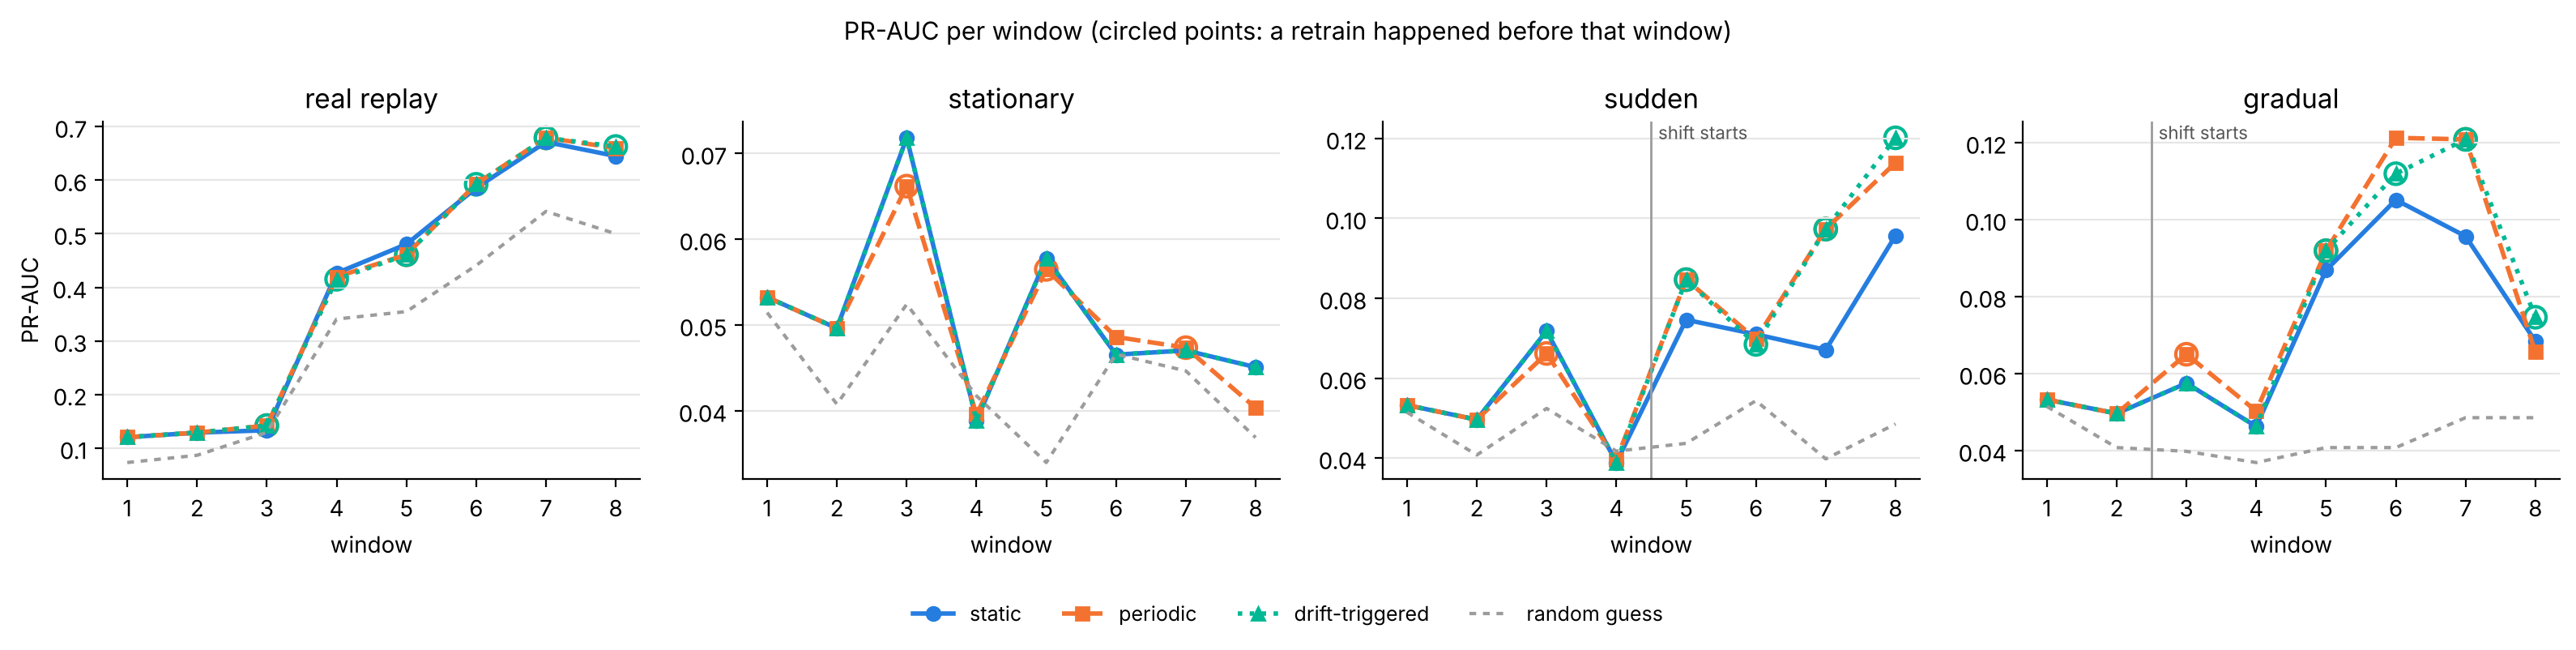

In [7]:
colors = {'static': '#257de0', 'periodic': '#f47230', 'drift_triggered': '#00b894'}
styles = {'static': '-', 'periodic': '--', 'drift_triggered': ':'}
markers = {'static': 'o', 'periodic': 's', 'drift_triggered': '^'}
scenarios = ['real_replay', 'stationary', 'sudden', 'gradual']
view = results.query("model == 'Logistic Regression' and seed == @SEEDS[0]")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=False)
for ax, name in zip(axes, scenarios):
    part = view[view['scenario'] == name]
    for strategy in STRATEGIES:
        s = part[part['strategy'] == strategy]
        ax.plot(s['window'], s['pr_auc'], styles[strategy], color=colors[strategy], marker=markers[strategy],
                markersize=6, linewidth=2, label=strategy.replace('_', '-'))
        retrains = s[s['retrained']]
        ax.scatter(retrains['window'], retrains['pr_auc'], s=90, facecolors='none', edgecolors=colors[strategy],
                   linewidths=1.5)
    base = part[part['strategy'] == 'static']
    ax.plot(base['window'], base['random_pr_auc'], color='#9c9c9c', linestyle=(0, (2, 2)), linewidth=1.5,
            label='random guess')
    change = part['change_window'].dropna()
    if len(change):
        ax.axvline(change.iloc[0] - 0.5, color='#9c9c9c', linewidth=1)
        ax.text(change.iloc[0] - 0.4, ax.get_ylim()[1], 'shift starts', va='top', fontsize=8, color='#555555')
    ax.set_title(name.replace('_', ' '))
    ax.set_xlabel('window')
    ax.set_xticks(range(1, N_STREAM_WINDOWS + 1))
    ax.grid(axis='y', color='#e6e6e6', linewidth=0.8)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel('PR-AUC')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('PR-AUC per window (circled points: a retrain happened before that window)', fontsize=11)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(root / 'figures' / '13_strategies_pr_auc_check.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Retrains, alerts and skipped retrains per run (seed 42)

`retrain_skipped_no_new_labels` counts windows where the rule asked for a retrain but no new labelled window had arrived yet (with a label delay of 1, the first two stream windows have no stream labels).

In [8]:
(results.query('seed == @SEEDS[0]')
 .groupby(['scenario', 'model', 'strategy'], observed=True)
 .agg(alerts=('alert', 'sum'), retrains=('retrained', 'sum'),
      skipped_no_new_labels=('retrain_skipped_no_new_labels', 'sum'),
      economic_alerts=('economic_alert', 'sum'), retrain_seconds=('retrain_seconds', 'sum'))
 .round(3))

alerts  retrains  skipped_no_new_labels  economic_alerts  retrain_seconds
scenario    model               strategy                                                                                  
gradual     Linear SVM          drift_triggered       4         4                      0                0            1.403
                                periodic              4         3                      0                0            0.932
                                static                4         0                      0                0            0.000
            Logistic Regression drift_triggered       4         4                      0                0            0.988
                                periodic              4         3                      0                0            0.762
                                static                4         0                      0                0            0.000
real_replay Linear SVM          drift_triggered       8         6                      2                8            1.989
                                periodic              8         3                      0                8            1.049
                                static                8         0                      0                8            0.000
            Logistic Regression drift_triggered       8         6                      2                8            3.123
                                periodic              8         3                      0                8            1.516
                                static                8         0                      0                8            0.000
stationary  Linear SVM          drift_triggered       0         0                      0                0            0.000
                                periodic              0         3                      0                0            0.947
                                static                0         0                      0                0            0.000
            Logistic Regression drift_triggered       0         0                      0                0            0.000
                                periodic              0         3                      0                0            0.747
                                static                0         0                      0                0            0.000
sudden      Linear SVM          drift_triggered       4         4                      0                0            1.292
                                periodic              4         3                      0                0            0.844
                                static                4         0                      0                0            0.000
            Logistic Regression drift_triggered       4         4                      0                0            1.129
                                periodic              4         3                      0                0            0.706
                                static                4         0                      0                0            0.000

## Notes and limitations

- All stream settings are PROPOSED defaults (see `DECISIONS.md`); results depend on them.
- **Drift-triggered with an expanding reference keeps firing after a shift.** After a retrain, the drift reference is all labelled rows so far, which are still mostly old rows. A shifted window therefore keeps differing from the reference, and the strategy retrains on every following window. This is a property of the proposed rule (PSI against the training rows), not a bug, and it should be discussed in the report.
- Alerts are logged for every strategy against that strategy's own current training rows. Only drift-triggered acts on them. Economic-indicator alerts are logged separately and never trigger a retrain, because the economic indicators are not model inputs.
- The decision threshold is re-tuned at every fit on the most recent labelled rows, so F1, precision and recall are threshold-dependent; PR-AUC is the primary metric.
- Synthetic scenarios are controlled experiments, not historical evidence.